In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

assert ".venv" in sys.executable, "Wrong kernel! Switch to 'Python (f1-tyre-strategy)' (top right)."
PROJECT_ROOT = Path.cwd().parent
assert PROJECT_ROOT.name == "f1-tyre-strategy-simulator", "Notebook isn't in the notebooks/ folder!"

RACES_DIR = PROJECT_ROOT / "data" / "raw" / "races"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
print("✅ Kernel and paths OK")

✅ Kernel and paths OK


In [2]:
files = sorted(RACES_DIR.glob("*.parquet"))
print("Race files found:", len(files))

df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print("Combined shape (rows, columns):", df.shape)
print(f"Memory used: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

Race files found: 92
Combined shape (rows, columns): (101291, 30)
Memory used: 62 MB


In [3]:
expected = {2022: 22, 2023: 22, 2024: 24, 2025: 24}
races_per_year = df.groupby("Year")["Round"].nunique()
print(races_per_year)

for year, n in expected.items():
    found = races_per_year.get(year, 0)
    assert found == n, f"{year}: expected {n} races, found {found}"
print("✅ All seasons complete:", races_per_year.sum(), "races")

Year
2022    22
2023    22
2024    24
2025    24
Name: Round, dtype: int64
✅ All seasons complete: 92 races


In [4]:
# One row per driver per race (driver-level columns are repeated on every lap)
driver_rows = df.drop_duplicates(["Year", "Round", "Driver"])

race_summary = driver_rows.groupby(["Year", "Round", "EventName"]).agg(
    Drivers=("Driver", "count"),
    QualiTimes=("BestQualiSeconds", lambda s: s.notna().sum()),
)
race_summary["Laps"] = df.groupby(["Year", "Round", "EventName"])["LapNumber"].max().astype(int)
race_summary["Winner"] = (
    driver_rows[driver_rows["FinishPosition"] == 1]
    .set_index(["Year", "Round", "EventName"])["Driver"]
)
race_summary = race_summary.reset_index()
print(race_summary.head(10).to_string(index=False))

# Spot-check winners we know are correct
known = [
    (2022, "Bahrain Grand Prix", "LEC"),
    (2023, "Bahrain Grand Prix", "VER"),
    (2024, "Monaco Grand Prix", "LEC"),
    (2025, "Australian Grand Prix", "NOR"),
]
print()
for year, event, driver in known:
    found = race_summary.loc[
        (race_summary["Year"] == year) & (race_summary["EventName"] == event), "Winner"
    ]
    assert len(found) == 1 and found.iloc[0] == driver, f"{year} {event}: expected {driver}, got {found.tolist()}"
    print(f"✅ {year} {event}: winner {driver}")

 Year  Round                 EventName  Drivers  QualiTimes  Laps Winner
 2022      1        Bahrain Grand Prix       20          20    57    LEC
 2022      2  Saudi Arabian Grand Prix       18          18    50    VER
 2022      3     Australian Grand Prix       20          19    58    LEC
 2022      4 Emilia Romagna Grand Prix       20          19    63    VER
 2022      5          Miami Grand Prix       20          19    57    VER
 2022      6        Spanish Grand Prix       20          20    66    VER
 2022      7         Monaco Grand Prix       20          20    64    PER
 2022      8     Azerbaijan Grand Prix       20          20    51    VER
 2022      9       Canadian Grand Prix       20          20    70    VER
 2022     10        British Grand Prix       20          20    52    SAI

✅ 2022 Bahrain Grand Prix: winner LEC
✅ 2023 Bahrain Grand Prix: winner VER
✅ 2024 Monaco Grand Prix: winner LEC
✅ 2025 Australian Grand Prix: winner NOR


In [5]:
print("Races with fewer than 20 drivers:")
print(race_summary[race_summary["Drivers"] < 20].to_string(index=False))

print("\nRaces where some drivers have no qualifying time:")
print(race_summary[race_summary["QualiTimes"] < race_summary["Drivers"]].to_string(index=False))

Races with fewer than 20 drivers:
 Year  Round                EventName  Drivers  QualiTimes  Laps Winner
 2022      2 Saudi Arabian Grand Prix       18          18    50    VER
 2023     14       Italian Grand Prix       19          19    51    VER
 2023     15     Singapore Grand Prix       19          19    62    SAI
 2023     17         Qatar Grand Prix       19          19    57    VER
 2023     20     São Paulo Grand Prix       19          19    71    VER
 2024      3    Australian Grand Prix       19          19    58    SAI
 2024     12       British Grand Prix       19          19    52    HAM
 2024     21     São Paulo Grand Prix       19          19    69    VER
 2025      9       Spanish Grand Prix       19          19    66    PIA
 2025     11      Austrian Grand Prix       19          19    70    NOR
 2025     12       British Grand Prix       19          19    52    NOR
 2025     16       Italian Grand Prix       19          19    53    VER

Races where some drivers have

In [6]:
# New columns (originals unchanged)
df["IsWetTyre"] = df["Compound"].isin(["INTERMEDIATE", "WET"])
df["RainfallFlag"] = df["Rainfall"].fillna(False).astype(bool)

wet = df.groupby(["Year", "EventName"]).agg(
    WetTyreLapShare=("IsWetTyre", "mean"),
    AnyRainfall=("RainfallFlag", "max"),
).reset_index()
wet = wet[(wet["WetTyreLapShare"] > 0) | wet["AnyRainfall"]]

print("Races with any wet-tyre laps or rainfall:", len(wet))
print(wet.sort_values("WetTyreLapShare", ascending=False).round(3).to_string(index=False))

print("\nCompound counts (all laps):")
print(df["Compound"].value_counts(dropna=False))

Races with any wet-tyre laps or rainfall: 16
 Year                 EventName  WetTyreLapShare  AnyRainfall
 2022       Japanese Grand Prix            1.000         True
 2024      São Paulo Grand Prix            1.000         True
 2025     Australian Grand Prix            0.809         True
 2025        British Grand Prix            0.737         True
 2024       Canadian Grand Prix            0.665         True
 2022      Singapore Grand Prix            0.622        False
 2022         Monaco Grand Prix            0.338         True
 2023         Monaco Grand Prix            0.293         True
 2022 Emilia Romagna Grand Prix            0.291        False
 2025        Belgian Grand Prix            0.273        False
 2023          Dutch Grand Prix            0.244         True
 2024        British Grand Prix            0.244         True
 2022      Hungarian Grand Prix            0.000         True
 2023        Belgian Grand Prix            0.000         True
 2024        Spanish Gran

In [7]:
# New flag columns (TrackStatus unchanged)
status = df["TrackStatus"].astype(str)
df["IsSafetyCar"] = status.str.contains("4")
df["IsVSC"] = status.str.contains("6") | status.str.contains("7")
df["IsRedFlag"] = status.str.contains("5")

# Count race laps (not driver-laps) with each neutralisation
flag_cols = ["IsSafetyCar", "IsVSC", "IsRedFlag"]
neutral = (
    df.groupby(["Year", "Round", "EventName", "LapNumber"])[flag_cols].any()
      .groupby(["Year", "Round", "EventName"]).sum()
)

print("Share of races with at least one lap of each:")
print((neutral[flag_cols] > 0).mean().round(2))

print("\nRaces with the most safety-car laps:")
print(neutral.sort_values("IsSafetyCar", ascending=False).head(8).to_string())

Share of races with at least one lap of each:
IsSafetyCar    0.55
IsVSC          0.46
IsRedFlag      0.11
dtype: float64

Races with the most safety-car laps:
                                      IsSafetyCar  IsVSC  IsRedFlag
Year Round EventName                                               
2025 1     Australian Grand Prix               22      0          0
     15    Dutch Grand Prix                    15      3          0
2024 23    Qatar Grand Prix                    13      1          0
     9     Canadian Grand Prix                 13      0          0
2022 21    São Paulo Grand Prix                13      4          0
2023 13    Dutch Grand Prix                    10      3          2
2025 7     Emilia Romagna Grand Prix            9      4          0
2023 3     Australian Grand Prix                9      2          4


In [8]:
DRY = ["SOFT", "MEDIUM", "HARD"]

eda = df[
    df["Compound"].isin(DRY)
    & df["PitInTime"].isna()
    & df["PitOutTime"].isna()
    & (df["LapNumber"] > 1)
    & df["IsAccurate"].eq(True)
    & ~(df["IsSafetyCar"] | df["IsVSC"] | df["IsRedFlag"])
    & df["BestQualiSeconds"].notna()
    & df["LapTimeSeconds"].notna()
].copy()

# New column: our target
eda["DeltaToQuali"] = eda["LapTimeSeconds"] - eda["BestQualiSeconds"]

print(f"Clean dry laps kept: {len(eda):,} of {len(df):,} ({len(eda) / len(df):.0%})")
print(eda["DeltaToQuali"].describe().round(2))

# Test the 'wet qualifying' risk: race laps FASTER than qualifying shouldn't happen in the dry
neg = eda[eda["DeltaToQuali"] < 0]
print(f"\nLaps faster than the driver's own qualifying lap: {len(neg):,}")
print(neg.groupby(["Year", "EventName"]).size().sort_values(ascending=False).head(10).to_string())

print(f"\nLaps more than 15 s slower than qualifying: {(eda['DeltaToQuali'] > 15).sum():,}")

Clean dry laps kept: 80,702 of 101,291 (80%)
count    80702.00
mean         5.28
std          4.25
min        -34.04
25%          4.71
50%          5.89
75%          7.11
max         70.87
Name: DeltaToQuali, dtype: float64

Laps faster than the driver's own qualifying lap: 5,363
Year  EventName                
2023  Canadian Grand Prix          1075
2022  Canadian Grand Prix          1029
2025  Las Vegas Grand Prix          760
2024  Belgian Grand Prix            751
2022  British Grand Prix            657
2023  Dutch Grand Prix              408
      Belgian Grand Prix            323
2022  Singapore Grand Prix          135
2024  British Grand Prix             77
2022  Emilia Romagna Grand Prix      61

Laps more than 15 s slower than qualifying: 245


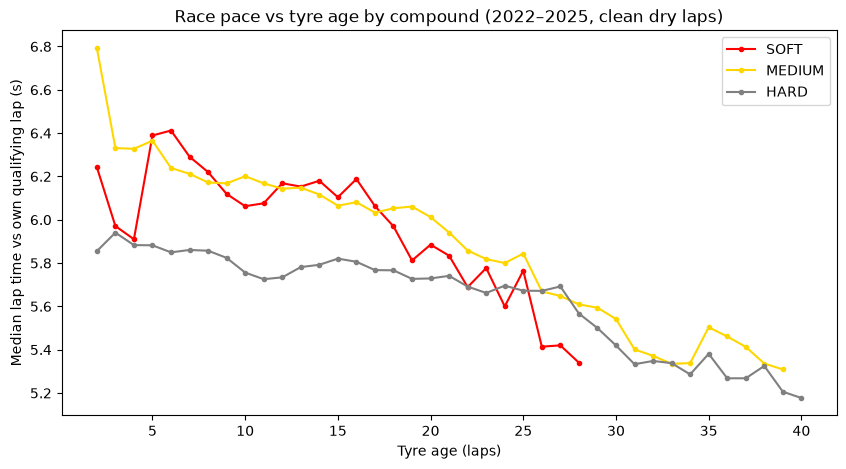

Median DeltaToQuali at selected tyre ages (s):
          SOFT  MEDIUM  HARD
TyreLife                    
3.0       5.97    6.33  5.94
10.0      6.06    6.20  5.76
20.0      5.88    6.01  5.73
30.0       NaN    5.54  5.42


In [9]:
colours = {"SOFT": "red", "MEDIUM": "gold", "HARD": "grey"}

fig, ax = plt.subplots(figsize=(10, 5))
curves = {}
for comp in DRY:
    sub = eda[(eda["Compound"] == comp) & (eda["TyreLife"] <= 40)]
    curve = sub.groupby("TyreLife")["DeltaToQuali"].agg(["median", "count"])
    curve = curve[curve["count"] >= 50]  # only tyre ages with enough laps to trust
    curves[comp] = curve["median"]
    ax.plot(curve.index, curve["median"], marker="o", ms=3, color=colours[comp], label=comp)

ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Median lap time vs own qualifying lap (s)")
ax.set_title("Race pace vs tyre age by compound (2022–2025, clean dry laps)")
ax.legend()
fig.savefig(FIG_DIR / "01_delta_vs_tyre_age.png", dpi=150, bbox_inches="tight")
plt.show()

print("Median DeltaToQuali at selected tyre ages (s):")
print(pd.DataFrame(curves).loc[lambda t: t.index.isin([3, 10, 20, 30])].round(2))

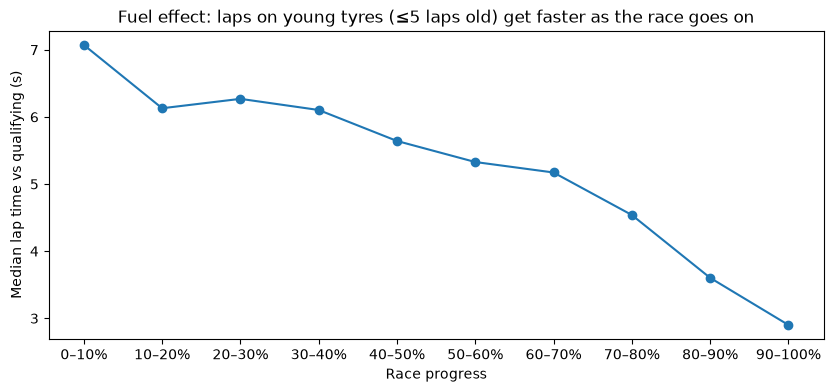

Races used: 87
Median change in lap time per lap (young tyres): -0.066 s/lap
Middle 50% of races: -0.089 to -0.051 s/lap


In [10]:
# New column: how far through the race each lap is (0 = start, 1 = finish)
eda["RaceProgress"] = eda["LapNumber"] / eda.groupby(["Year", "Round"])["LapNumber"].transform("max")

# Only laps on tyres 5 laps old or younger, so tyre wear barely varies
fresh = eda[eda["TyreLife"] <= 5]
bins = np.linspace(0, 1, 11)
fuel_curve = fresh.groupby(pd.cut(fresh["RaceProgress"], bins), observed=True)["DeltaToQuali"].median()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot([f"{int(b.left * 100)}–{int(b.right * 100)}%" for b in fuel_curve.index], fuel_curve.values, marker="o")
ax.set_xlabel("Race progress")
ax.set_ylabel("Median lap time vs qualifying (s)")
ax.set_title("Fuel effect: laps on young tyres (≤5 laps old) get faster as the race goes on")
fig.savefig(FIG_DIR / "01_fuel_effect.png", dpi=150, bbox_inches="tight")
plt.show()

# Estimate the fuel effect in seconds per lap, race by race, then take the median
slopes = []
for (year, rnd), g in fresh.groupby(["Year", "Round"]):
    if len(g) >= 30 and g["LapNumber"].nunique() >= 10:
        slopes.append(np.polyfit(g["LapNumber"], g["DeltaToQuali"], 1)[0])
slopes = pd.Series(slopes)
print(f"Races used: {len(slopes)}")
print(f"Median change in lap time per lap (young tyres): {slopes.median():+.3f} s/lap")
print(f"Middle 50% of races: {slopes.quantile(0.25):+.3f} to {slopes.quantile(0.75):+.3f} s/lap")

Circuits (Location) and number of races:
Location
Sakhir               4
Spielberg            4
Yas Island           4
Mexico City          4
Austin               4
Marina Bay           4
Monza                4
Zandvoort            4
Spa-Francorchamps    4
Jeddah               4
Budapest             4
Silverstone          4
Montréal             4
Baku                 4
Monaco               4
Barcelona            4
Melbourne            4
Miami                3
Imola                3
São Paulo            3
Suzuka               3
Lusail               3
Las Vegas            3
Shanghai             2
Le Castellet         1


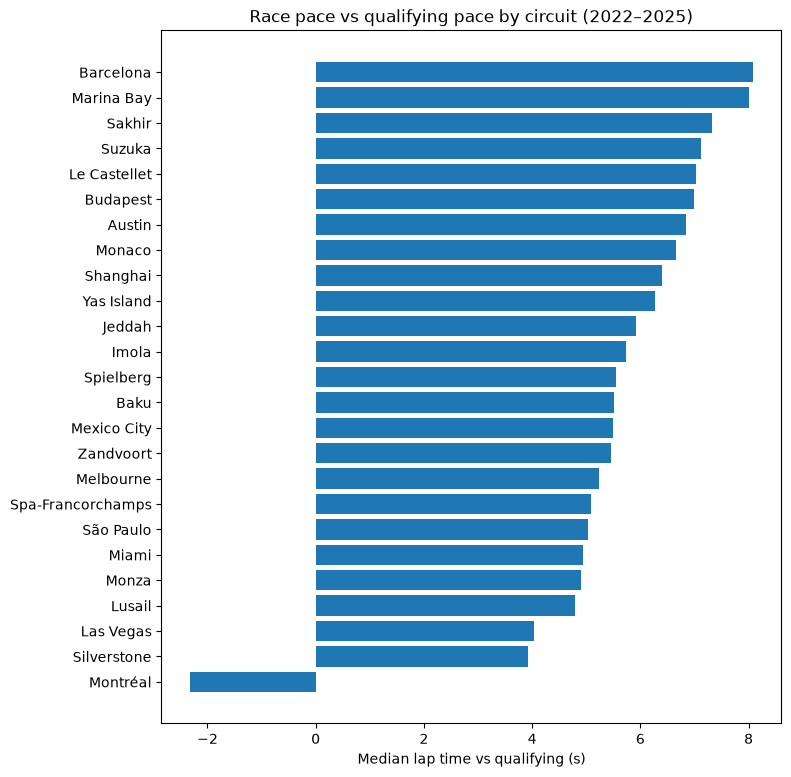


Smallest gaps:
Location
Montréal      -2.33
Silverstone    3.93
Las Vegas      4.03

Largest gaps:
Location
Sakhir        7.32
Marina Bay    8.00
Barcelona     8.09


In [11]:
print("Circuits (Location) and number of races:")
print(eda.drop_duplicates(["Year", "Round"])["Location"].value_counts().to_string())

track = eda.groupby("Location")["DeltaToQuali"].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(track.index, track.values)
ax.set_xlabel("Median lap time vs qualifying (s)")
ax.set_title("Race pace vs qualifying pace by circuit (2022–2025)")
fig.savefig(FIG_DIR / "01_delta_by_track.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSmallest gaps:")
print(track.head(3).round(2).to_string())
print("\nLargest gaps:")
print(track.tail(3).round(2).to_string())

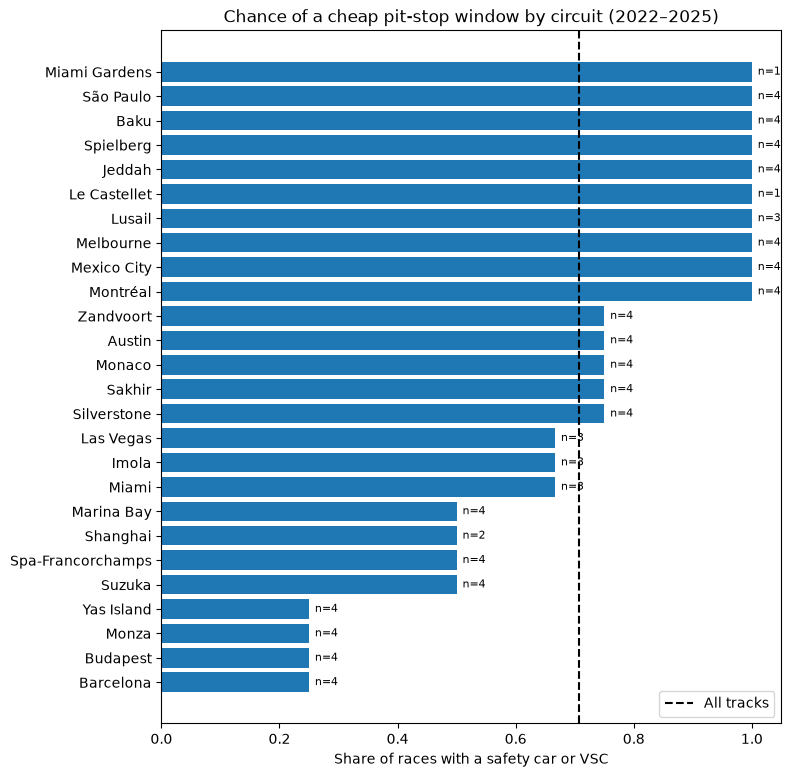

All tracks: 71% of races had a safety car or VSC
                   Races  SCRaces  SCorVSCRaces  SCorVSCRate
Location                                                    
Miami Gardens          1        0             1         1.00
São Paulo              4        4             4         1.00
Baku                   4        2             4         1.00
Spielberg              4        2             4         1.00
Jeddah                 4        4             4         1.00
Le Castellet           1        1             1         1.00
Lusail                 3        3             3         1.00
Melbourne              4        3             4         1.00
Mexico City            4        2             4         1.00
Montréal               4        4             4         1.00
Austin                 4        2             3         0.75
Zandvoort              4        3             3         0.75
Monaco                 4        2             3         0.75
Sakhir                 4        2   

In [12]:
race_loc = df.drop_duplicates(["Year", "Round"])[["Year", "Round", "Location"]]

sc = neutral.reset_index()
sc["HadSC"] = sc["IsSafetyCar"] > 0
sc["HadSCorVSC"] = (sc["IsSafetyCar"] > 0) | (sc["IsVSC"] > 0)
sc = sc.merge(race_loc, on=["Year", "Round"], how="left")

sc_track = sc.groupby("Location").agg(
    Races=("HadSC", "size"),
    SCRaces=("HadSC", "sum"),
    SCorVSCRaces=("HadSCorVSC", "sum"),
)
sc_track["SCorVSCRate"] = sc_track["SCorVSCRaces"] / sc_track["Races"]
sc_track = sc_track.sort_values("SCorVSCRate")

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(sc_track.index, sc_track["SCorVSCRate"])
for i, (rate, n) in enumerate(zip(sc_track["SCorVSCRate"], sc_track["Races"])):
    ax.text(rate + 0.01, i, f"n={n}", va="center", fontsize=8)
ax.axvline(sc["HadSCorVSC"].mean(), linestyle="--", color="black", label="All tracks")
ax.set_xlabel("Share of races with a safety car or VSC")
ax.set_title("Chance of a cheap pit-stop window by circuit (2022–2025)")
ax.legend()
fig.savefig(FIG_DIR / "01_sc_vsc_rate_by_track.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"All tracks: {sc['HadSCorVSC'].mean():.0%} of races had a safety car or VSC")
print(sc_track.sort_values("SCorVSCRate", ascending=False).round(2).to_string())